# Scenario 2 — Website Analytics Debug
**Lab:** Generative AI for Data Science · **Focus:** error diagnosis, robust data validation, correct session-level metrics, clear summaries

**Original problem:** Marketing reports impossible engagement metrics, including bounce rates above 100% and negative session times. The source example groups event logs by `session_id` but mixes per-event and per-session metrics. No real logs were supplied, so we validate on **synthetic event data**.

**Data grain used:** **one row per page event**. `page_views` is the number of views attributable to that event (usually 1); `duration` is **seconds** attributable to that event. Under a different event schema, calculation rules must change.

## 1. Your Prompt — first iteration

> **Role:** Act as a senior product analytics engineer and Python debugging specialist. Diagnose the following function that returns impossible bounce rates and session times. Explain separately what is wrong with bounce rate, duration, per-session page views, and device aggregation; supply corrected pandas code. Assume multiple event rows per `session_id` and fields `session_id`, `page_views`, `duration`, `device_type`.

```python
def analyze_user_engagement(logs_df):
    metrics = {
        'bounce_rate': logs_df.groupby('session_id')['page_views'].apply(
            lambda x: x == 1).mean(),
        'avg_session_time': logs_df.groupby('session_id')['duration'].sum(),
        'pages_per_session': logs_df.groupby('session_id')['page_views'].mean()
    }
    device_metrics = logs_df.groupby('device_type').agg({
        'session_id': 'count', 'duration': 'mean', 'page_views': 'sum'
    })
    return metrics, device_metrics
```

**Why this prompt:** It includes the broken code, observed symptoms, data grain, an expert role, and precise metrics to fix. This enables actual diagnosis, not a generic rewrite.

## 2. Generated Code — first suggested correction (retained for comparison)

```python
def draft_corrected_metrics(df):
    sessions = df.groupby('session_id').agg(
        views=('page_views', 'sum'),
        duration_seconds=('duration', 'sum'),
        device=('device_type', 'first')
    )
    bounce_rate = sessions.views.eq(1).mean() * 100
    avg_session_time = sessions.duration_seconds.mean()
    pages_per_session = sessions.views.mean()
    return bounce_rate, avg_session_time, pages_per_session
```

**Review:** Aggregating to sessions before calculating averages fixes the grain mismatch. However, the draft still trusts negative durations, nonnumeric values, inconsistent device assignments, and malformed session IDs. It also does not return device summaries or visualizations. The original boolean `.mean()` *cannot itself exceed 100%*; such a result would require another scaling/aggregation error or different code path, so we should not assert that this single line caused it.

## 3. Follow-up Prompts — diagnostic refinement

**Follow-up A:** “Explain specifically why the original logic is wrong, and distinguish symptoms demonstrated by the code from those that require investigating other pipeline stages. Add strict required-column checks, numeric casting, nonnegative duration and page-view validation, consistent device assignment per session, and a configurable policy for invalid rows (raise or quarantine with an audit count).”

**Follow-up B:** “Make `bounce_rate_pct` equal to the percentage of **sessions** with exactly one page view; compute average session time in seconds after aggregating each session; use distinct sessions per device, and add plots, assertions, and one synthetic invalid row to test error handling. Avoid silently manufacturing negative time corrections.”

**Why refine?** Directly debugging definitions and grain prevents valid-looking but incorrect rates. Explicit data-quality rules allow the marketing team to trace failures back to source events.

## 4. Final Solution — example event log

To use real logs, provide a file `website_logs.csv` with the four columns below. Records are expected to be page-level events, not one aggregated row per session.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

source_path = Path('website_logs.csv')
if source_path.exists():
    logs_df = pd.read_csv(source_path)
    print(f'Real file loaded: {source_path}')
else:
    logs_df = pd.DataFrame([
        ('S01',1,20,'mobile'),
        ('S02',1,80,'desktop'), ('S02',1,40,'desktop'),
        ('S03',1,0,'mobile'),
        ('S04',1,30,'mobile'), ('S04',1,20,'mobile'), ('S04',1,10,'mobile'),
        ('S05',1,10,'desktop'), ('S05',1,10,'desktop'),
        ('S06',1,-15,'mobile'),  # deliberately invalid row for demonstration
    ], columns=['session_id','page_views','duration','device_type'])
    print('Synthetic event-level test data loaded — not actual website logs')
print(logs_df.to_string(index=False))

Synthetic event-level test data loaded — not actual website logs
session_id  page_views  duration device_type
       S01           1        20      mobile
       S02           1        80     desktop
       S02           1        40     desktop
       S03           1         0      mobile
       S04           1        30      mobile
       S04           1        20      mobile
       S04           1        10      mobile
       S05           1        10     desktop
       S05           1        10     desktop
       S06           1       -15      mobile


In [2]:
def analyze_user_engagement(logs_df: pd.DataFrame, strict: bool = True):
    """Compute session-level engagement metrics from per-event page logs.

    Required: session_id, page_views (event increment), duration (seconds),
    device_type. strict=True raises on bad rows; strict=False quarantines them
    and returns an audit trail. A session must have only one device_type.
    """
    required = ['session_id','page_views','duration','device_type']
    missing = [x for x in required if x not in logs_df]
    if missing:
        raise ValueError(f'Missing required columns: {missing}')
    work = logs_df[required].copy()
    work['session_id'] = work['session_id'].astype('string').str.strip()
    work['device_type'] = work['device_type'].astype('string').str.strip()
    work['page_views'] = pd.to_numeric(work['page_views'], errors='coerce')
    work['duration'] = pd.to_numeric(work['duration'], errors='coerce')
    valid = (
        work['session_id'].notna() & work['session_id'].ne('') &
        work['device_type'].notna() & work['device_type'].ne('') &
        work['page_views'].notna() & work['duration'].notna() &
        np.isfinite(work['page_views']) & np.isfinite(work['duration']) &
        work['page_views'].ge(0) & work['duration'].ge(0) &
        np.equal(work['page_views'], np.floor(work['page_views']))
    )
    audit = {
        'input_event_rows': int(len(work)),
        'invalid_event_rows': int((~valid).sum()),
    }
    if strict and audit['invalid_event_rows']:
        bad_indexes = work.index[~valid].tolist()
        raise ValueError(f'{len(bad_indexes)} invalid event row(s): {bad_indexes}')
    clean = work.loc[valid].copy()
    if clean.empty:
        raise ValueError('No valid event rows to aggregate')
    if clean.groupby('session_id')['device_type'].nunique().gt(1).any():
        raise ValueError('Some sessions have conflicting device assignments')

    # First aggregate all events to *one row per unique session*.
    sessions = (clean.groupby('session_id', as_index=False)
        .agg(page_views=('page_views','sum'),
             duration_seconds=('duration','sum'),
             device_type=('device_type','first')))
    sessions['bounce'] = sessions['page_views'].eq(1)
    total_sessions = len(sessions)
    metrics = {
        'sessions': int(total_sessions),
        'bounce_rate_pct': float(100 * sessions['bounce'].mean()),
        'avg_session_time_seconds': float(sessions['duration_seconds'].mean()),
        'pages_per_session': float(sessions['page_views'].mean()),
    }
    device_metrics = (sessions.groupby('device_type', as_index=False)
        .agg(sessions=('session_id','nunique'),
             bounce_rate_pct=('bounce', lambda col: 100 * col.mean()),
             avg_session_time_seconds=('duration_seconds','mean'),
             pages_per_session=('page_views','mean')))
    audit['valid_event_rows'] = int(len(clean))
    audit['valid_sessions'] = int(total_sessions)
    return metrics, sessions, device_metrics, audit

# Non-strict mode quarantines the one intentionally invalid event.
metrics, sessions, device_metrics, audit = analyze_user_engagement(logs_df, strict=False)
print('Summary:', metrics)
print('Data quality:', audit)
print('By device:')
print(device_metrics.to_string(index=False))

Summary: {'sessions': 5, 'bounce_rate_pct': 40.0, 'avg_session_time_seconds': 44.0, 'pages_per_session': 1.8}
Data quality: {'input_event_rows': 10, 'invalid_event_rows': 1, 'valid_event_rows': 9, 'valid_sessions': 5}
By device:
device_type  sessions  bounce_rate_pct  avg_session_time_seconds  pages_per_session
    desktop         2         0.000000                 70.000000           2.000000
     mobile         3        66.666667                 26.666667           1.666667


In [3]:
# Tests verify correct denominators, units, and error handling.
assert 0 <= metrics['bounce_rate_pct'] <= 100
assert (sessions['duration_seconds'] >= 0).all()
assert device_metrics['sessions'].sum() == metrics['sessions']
if not source_path.exists():
    assert metrics['sessions'] == 5
    assert metrics['bounce_rate_pct'] == 40.0
    assert metrics['avg_session_time_seconds'] == 44.0
    assert np.isclose(metrics['pages_per_session'], 1.8)
    assert audit['invalid_event_rows'] == 1
    try:
        analyze_user_engagement(logs_df, strict=True)
        raise AssertionError('Expected strict mode to flag negative duration')
    except ValueError:
        pass
print('Website engagement tests passed')

Website engagement tests passed


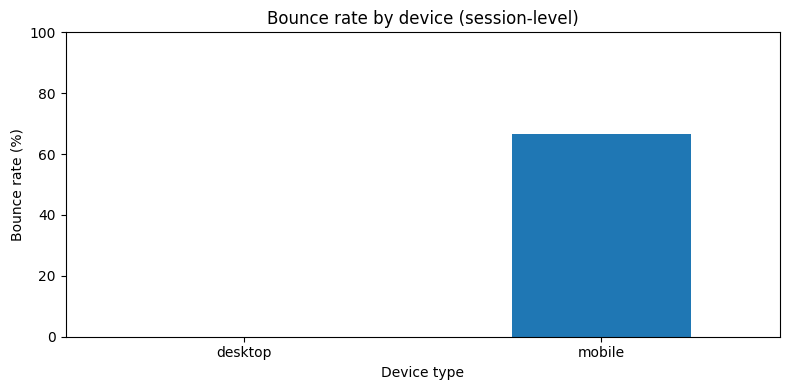

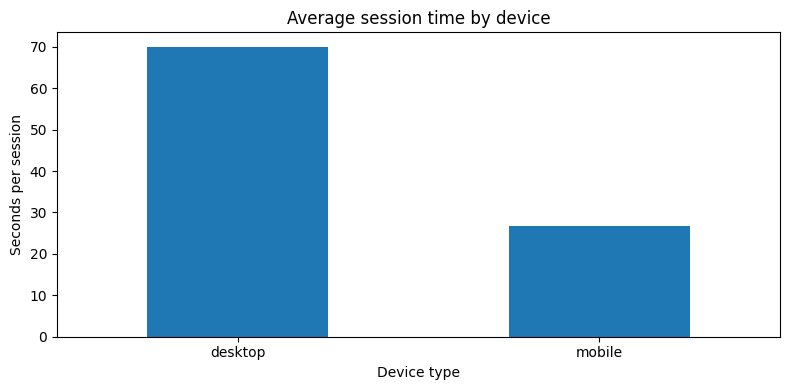

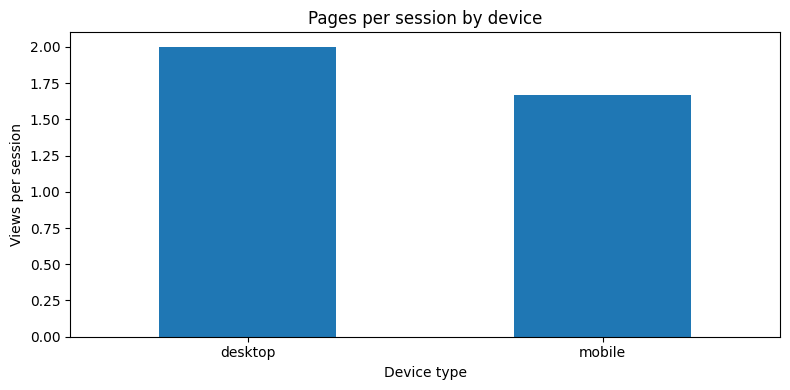

In [4]:
# Each visualization has one business question and explicit units.
ax = device_metrics.plot.bar(x='device_type', y='bounce_rate_pct', legend=False,
                             figsize=(8,4))
ax.set_title('Bounce rate by device (session-level)')
ax.set_xlabel('Device type')
ax.set_ylabel('Bounce rate (%)')
ax.set_ylim(0,100)
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

ax = device_metrics.plot.bar(x='device_type', y='avg_session_time_seconds',
                             legend=False, figsize=(8,4))
ax.set_title('Average session time by device')
ax.set_xlabel('Device type')
ax.set_ylabel('Seconds per session')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

ax = device_metrics.plot.bar(x='device_type', y='pages_per_session',
                             legend=False, figsize=(8,4))
ax.set_title('Pages per session by device')
ax.set_xlabel('Device type')
ax.set_ylabel('Views per session')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 5. Results and Discussion

**1. How did different prompts approach error identification?** The initial debugging request exposed a grain mismatch: the source function averaged event-level indicators and returned a Series of per-session durations instead of a site-wide average. The refined prompt required a step-by-step explanation, explicit session-level aggregation, and data-quality checks. The original `mean()` of Boolean values cannot itself yield over 100%; that symptom calls for checking subsequent percentage conversion, aggregation, or reporting code.

**2. What validation methods were suggested?** The final solution checks required columns, blank IDs, numeric types, finite values, nonnegative times, nonnegative integer view counts, and consistent device type per session. A strict mode raises a clear exception; a non-strict mode quarantines invalid rows and reports an audit count. Assertions confirm that bounce rates fall between 0% and 100%, device session counts reconcile, and the example produces expected metrics.

**3. How was time handling improved?** The code explicitly defines `duration` as seconds **per event**, sums it by session, then averages session totals. This prevents confusing event averages with session durations and rejects negative values rather than silently clipping them to zero. If the source has reliable session start/end timestamps, elapsed time should instead be computed from timezone-normalized timestamps; the present schema does not supply these fields.

**Peer discussion prompt:** Our fix assumes one row per page event. If a colleague's source already has one row per session, what changes in the bounce-rate and time calculations? Why is data grain the first thing to establish?

**Reflection:** More detailed prompts enabled traceable metrics, reproducible checks, and useful data-quality reporting instead of simply modifying calculations until the outputs looked plausible.